# Salario mínimo y empleo de los jóvenes

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "smi-empleo-juvenil"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Salario mínimo y empleo de los jóvenes"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Salario mínimo legal", "unidad": "% del salario mediano a tiempo completo"}
EJE_Y = {"titulo": "Tasa de empleo de 15 a 24 años", "unidad": "% de la población de 15 a 24 años"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con salario mínimo legal nacional y dato en los dos ejes.

- **Eje horizontal:** el **salario mínimo legal** en porcentaje del salario mediano de los trabajadores a tiempo completo del mismo país (el mismo indicador que la gráfica `smi-salario-mediano` de Empleo).
- **Eje vertical:** la **tasa de empleo de los jóvenes**: el porcentaje de la población de 15 a 24 años que tiene empleo.

**Para qué sirve.** Es el argumento de quienes sostienen que un salario mínimo alto reduce el empleo de quienes tienen menos experiencia, los jóvenes. Quienes defienden subirlo sostienen que reduce la pobreza de quienes trabajan y apenas afecta al empleo (la otra lectura está en `smi-pobreza-laboral`). **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- Solo entran los países con salario mínimo legal nacional: en los demás (como los países nórdicos, Austria, Italia o Suiza) los salarios mínimos se fijan por convenio colectivo y no hay dato.
- La tasa de empleo juvenil depende de cuántos jóvenes estudian: un país con muchos jóvenes en la universidad tiene una tasa baja sin que ello signifique que no encuentren trabajo.
- Los países difieren en la edad a la que se aplica el salario mínimo completo y en los mínimos reducidos para jóvenes, que el indicador no recoge.

## 2. Descarga

- **OCDE, Minimum relative to average wages of full-time workers** (`OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE`, versión 1.0): salario mínimo en % del salario mediano a tiempo completo (`MR_WG_FT`, `PT_WG_A_SAL_FT`, mediana).
- **OCDE, Encuestas de población activa** (`OECD.SDD.TPS,DSD_LFS@DF_IALFS_EMP_WAP_Q`, versión 1.0): tasa de empleo (`EMP_WAP`) de 15 a 24 años (`Y15T24`), total, media anual.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Salario mínimo legal en % del salario mediano a tiempo completo (OCDE, Minimum relative to average wages)
DATAFLOW_MIN = "OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE,1.0"
# Dimensiones: país . medida . unidad . periodo de pago . base de precios . operación estadística . sexo
CLAVE_MIN = "{AREA}.MR_WG_FT.PT_WG_A_SAL_FT._Z._Z.MEDIAN._Z"
# Tasa de empleo de 15 a 24 años (OCDE, Encuestas de población activa): media anual
DATAFLOW_EMP = "OECD.SDD.TPS,DSD_LFS@DF_IALFS_EMP_WAP_Q,1.0"
# Dimensiones: país . medida . unidad . transformación . ajuste . sexo . edad . actividad . frecuencia
CLAVE_EMP = "{AREA}.EMP_WAP.PT_WAP_SUB._Z.N._T.Y15T24._Z.A"

x, _ = oecd.get(DATAFLOW_MIN, CLAVE_MIN, areas=AREAS, desde=DESDE)
y, _ = oecd.get(DATAFLOW_EMP, CLAVE_EMP, areas=AREAS, desde=DESDE)
print("Países con salario mínimo:", x["serie"].nunique(), "· con tasa de empleo juvenil:", y["serie"].nunique())

Países con salario mínimo: 30 · con tasa de empleo juvenil: 38


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Sin punto de las medias:** el salario mínimo no se publica para la media OCDE ni para la UE-27 (solo existe en los países con salario mínimo legal).
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
4. Para las notas: los países de la OCDE sin salario mínimo legal nacional en la fuente.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_min(x):
    """Notas comunes del eje del salario mínimo (OCDE, MIN2AVE)."""
    _, flujo, version = DATAFLOW_MIN.split(",")
    return [
        f"Salario mínimo: OCDE, Minimum relative to average wages of full-time workers ({flujo}, versión {version}): "
        "salario mínimo legal nacional en porcentaje del salario mediano de los trabajadores a tiempo completo "
        "(MR_WG_FT, PT_WG_A_SAL_FT, mediana). Solo publica los países con salario mínimo legal nacional.",
        "En Estados Unidos, la OCDE usa el salario mínimo federal, que varios estados superan con el suyo.",
    ]


_, FLUJO_EMP, VERSION_EMP = DATAFLOW_EMP.split(",")
_, FLUJO_MIN, VERSION_MIN = DATAFLOW_MIN.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_MIN} (Minimum relative to average wages, versión {VERSION_MIN}): MR_WG_FT, PT_WG_A_SAL_FT, mediana", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_EMP} (Encuestas de población activa, versión {VERSION_EMP}): EMP_WAP, Y15T24, _T, media anual", oecd.URL_EXPLORER, HOY),
]
sin_minimo = sorted(nombre_punto(c) for c in set(PAISES) - set(x["serie"]))
NOTAS = notas_min(x) + [
    f"Tasa de empleo juvenil: OCDE, Encuestas de población activa ({FLUJO_EMP}, versión {VERSION_EMP}): personas "
    "ocupadas de 15 a 24 años en porcentaje de la población de esa edad, media anual.",
    f"La OCDE no publica salario mínimo para {len(sin_minimo)} de los {len(PAISES)} países del universo, que no tienen "
    "salario mínimo legal nacional (la lista está en la nota de países sin dato); en la mayoría de ellos los "
    "salarios mínimos se fijan por convenio colectivo.",
    "La tasa de empleo de los jóvenes depende de cuántos estudian: con muchos jóvenes en la universidad es baja sin "
    "que ello signifique que no encuentren trabajo.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

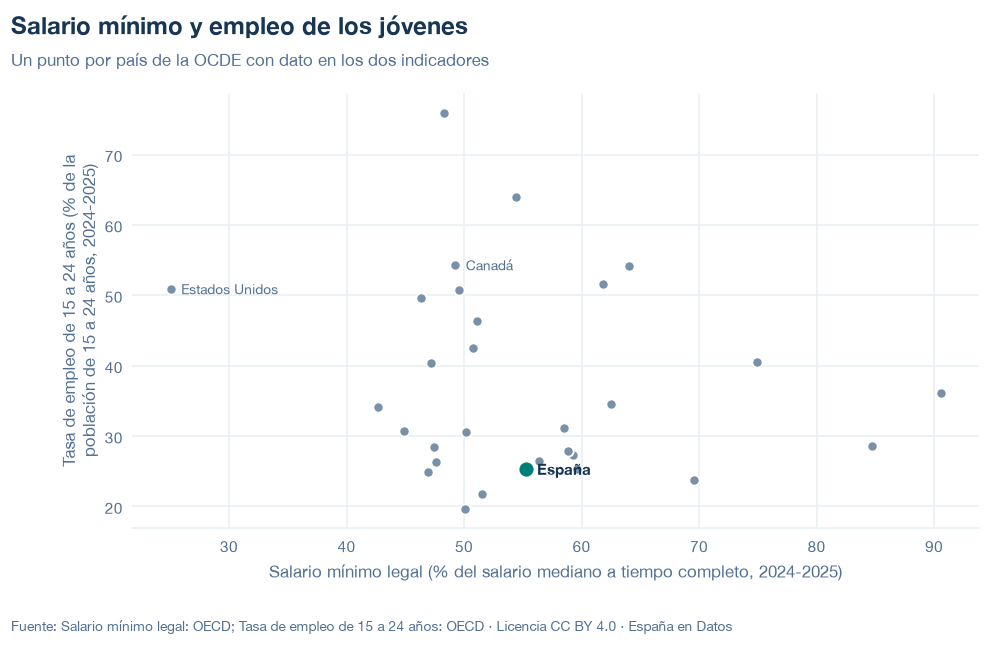

codigo  anio         x        y
   AUS  2025 54.451465 64.00074
   BEL  2025 47.470750 28.45000
   CAN  2025 49.242199 54.29167
   CHL  2024 69.538063 23.77360
   COL  2025 90.543835 36.19417
   CRI  2025 84.717361 28.63914
   CZE  2025 46.913413 24.90000
   DEU  2025 49.555057 50.80000
   ESP  2025 55.301258 25.32500
   EST  2025 42.698416 34.15000
   FRA  2025 62.483821 34.50000
   GBR  2025 61.854103 51.57500
   GRC  2025 50.101757 19.70000
   HUN  2025 47.625665 26.30000
   IRL  2025 51.120622 46.37500
   ISR  2025 50.746478 42.50834
   JPN  2025 46.364837 49.60750
   KOR  2025 59.568643 25.26242
   LTU  2025 50.135716 30.60000
   LUX  2025 56.352517 26.45000
   LVA  2025 44.848736 30.77500
   MEX  2025 74.927497 40.59032
   NLD  2025 48.296957 75.97500
   NZL  2025 64.049248 54.13208
   POL  2025 59.233037 27.35000
   PRT  2025 58.878413 27.92500
   SVK  2025 51.509323 21.72500
   SVN  2025 58.535604 31.12500
   TUR  2025 47.221081 40.32500
   USA  2024 25.017253 50.89007


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/smi-empleo-juvenil.json y data/smi-empleo-juvenil.csv


## 6. Fuentes, notas y licencia

- OCDE, Minimum relative to average wages of full-time workers: `OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE,1.0` (`MR_WG_FT`, `PT_WG_A_SAL_FT`, `MEDIAN`).
- OCDE, Encuestas de población activa: `OECD.SDD.TPS,DSD_LFS@DF_IALFS_EMP_WAP_Q,1.0` (`EMP_WAP`, `PT_WAP_SUB`, `Y15T24`, `_T`, frecuencia anual).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.